# Perbandingan Aquila Optimizer dan Grey Wolf Optimizer dalam Tuning Random Forest untuk Deteksi Diabetes Gestasional

**Dataset:** Gestational Diabetes Mellitus (GDM) — Mendeley Data (DOI: 10.17632/k5c8rfgsn9/1)  
**Referensi:** Shahid, M.M., et al. (2026). *Endocrinology, Diabetes & Metabolism*, 9(4), e70268.  

---
**Rumusan Masalah:**
1. Fitur apa yang paling berpengaruh terhadap deteksi diabetes gestasional berdasarkan analisis *feature importance* pada model Random Forest dengan performa terbaik? &rarr; **bagian 9.7**
2. Bagaimana perbandingan performa Random Forest hasil tuning Aquila Optimizer dan Grey Wolf Optimizer berdasarkan accuracy, precision, recall, F1-score, ROC-AUC, dan waktu komputasi? &rarr; **bagian 9.2c**

**Alur Penelitian:**
1. Pengumpulan & Persiapan Data
2. Preprocessing awal (cleaning, seleksi fitur, encoding target)
3. Pembagian data 80:20 (tanpa SMOTE)
4. Imputasi median (dihitung hanya dari data latih) dan pembentukan fitur BMI
5. RF Baseline (tanpa tuning), hanya sebagai pembanding referensi, tidak ikut pemilihan model terbaik
6. Tuning RF dengan Grey Wolf Optimizer (GWO)
7. Tuning RF dengan Aquila Optimizer (AO), dengan anggaran evaluasi yang disamakan dengan GWO
8. Perbandingan AO vs GWO (RM 2) dan feature importance model terbaik (RM 1)


### Pemetaan Rumus Dasar Teori (Bab II) ke Kode

| Persamaan | Isi | Implementasi di notebook |
|---|---|---|
| 2.1 | Random Forest: $\hat{y} = \text{mode}\{h_1(x), \dots, h_N(x)\}$ | `prediksi_suara_terbanyak()` (bagian 6) |
| 2.2 | Optimasi: $\theta^* = \arg\max_{\theta \in \Omega} f(\theta)$ | `_fitness()` mengembalikan rata-rata F1 CV 5-fold dan dimaksimalkan; $\Omega$ = batas `lb`/`ub` |
| 2.3 | AO: $X_{t+1} = X_t + \Delta X_t$ | blok pembaruan posisi di `AquilaOptimizer.optimize()` |
| 2.4 - 2.7 | GWO: $D$, $X(t+1)$, $X_1, X_2, X_3$, rata-rata | blok pembaruan posisi di `GreyWolfOptimizer.optimize()` |
| 2.8 - 2.13 | Accuracy, Precision, Recall, F1, TPR, FPR | `hitung_metrik_manual()` (bagian 6) |
| Tabel 2.2 | TP, TN, FP, FN | `hitung_komponen_cm()` |
| 2.14 | $T = t_{selesai} - t_{mulai}$ | variabel `t_mulai` dan `t_selesai` pada tiap proses |


## 1. Instalasi dan Import Library

In [1]:
# Install library yang belum tersedia (Colab maupun VS Code)
!pip install pyreadstat mlflow -q
!pip install -q huggingface_hub

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pyreadstat
import warnings
import time
import random
import math


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, auc as hitung_auc
)
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

warnings.filterwarnings('ignore')
np.random.seed(42)
random.seed(42)

print('Library berhasil diimpor.')

Library berhasil diimpor.


## 2. Muat Dataset

In [3]:
from pathlib import Path

try:
    from google.colab import drive

    drive.mount('/content/drive')
    DI_COLAB = True
    ROOT = Path('/content')

    drive_file_path = (
        '/content/drive/MyDrive/'
        'Draft Skripsi/Diabetes /data.sav'
    )

except ImportError:
    DI_COLAB = False

    cwd = Path.cwd()
    ROOT = cwd.parent if cwd.name == 'notebooks' else cwd

    drive_file_path = str(ROOT / 'data' / 'data.sav')

print(f"Mode Colab: {DI_COLAB}")
print(f"Lokasi dataset: {drive_file_path}")
print(f"Dataset tersedia: {Path(drive_file_path).exists()}")

Mode Colab: False
Lokasi dataset: d:\SEMESTER 7\S WORD\gdm_ao_gwo_rf\data\data.sav
Dataset tersedia: True


In [4]:
# ---------------------------------------------------------------
# 2.1 Memuat dataset
# ---------------------------------------------------------------
# Muat file SPSS (.sav)
df_raw, meta = pyreadstat.read_sav(drive_file_path)

# Tampilkan semua kolom pada tabel
pd.set_option('display.max_columns', None)

print(f'Dimensi dataset awal: {df_raw.shape}')

# Tampilkan variabel dalam beberapa baris
columns = list(df_raw.columns)
print(f'\nVariabel dalam dataset ({len(columns)} kolom):')

for i in range(0, len(columns), 9):
    print(columns[i:i+9])

# Tampilkan 5 baris pertama dengan semua kolom
display(df_raw.head())

Dimensi dataset awal: (1782, 72)

Variabel dalam dataset (72 kolom):
['age', 'ag', 'address', 'arsenic', 'DMf', 'DMm', 'DMp', 'DMsibling', 'DMpf']
['DMmf', 'obesity', 'pcos', 'abortion', 'iud', 'nnd', 'prom', 'macrosomia', 'baby3.5']
['eclampsia', 'gdm', 'hypo', 'hyper', 'htn', 'polyH', 'primi', 'multiP', 'gttW1']
['gm', 'w4', 'w8', 'w12', 'w16', 'w20', 'w24', 'w28', 'w32']
['w36', 'w40', 'g8', 'g18', 'g28', 'g38', 'gttWeek2', 'first', 'second']
['third', 'ibw', 'ht', 'wt1', 'wt2', 'fbs1', 'h1.1', 'h2.1', 'gdm1']
['fhr1', 'fw1', 'afi1', 'bpd1', 'ac1', 'hc1', 'fl1', 'fbs2', 'h1.2']
['h2.2', 'gdm2', 'fhr2', 'fw2', 'afi2', 'bpd2', 'ac2', 'hc2', 'fl2']


,age,ag,address,arsenic,DMf,DMm,DMp,DMsibling,DMpf,DMmf,obesity,pcos,abortion,iud,nnd,prom,macrosomia,baby3.5,eclampsia,gdm,hypo,hyper,htn,polyH,primi,multiP,gttW1,gm,w4,w8,w12,w16,w20,w24,w28,w32,w36,w40,g8,g18,g28,g38,gttWeek2,first,second,third,ibw,ht,wt1,wt2,fbs1,h1.1,h2.1,gdm1,fhr1,fw1,afi1,bpd1,ac1,hc1,fl1,fbs2,h1.2,h2.2,gdm2,fhr2,fw2,afi2,bpd2,ac2,hc2,fl2
0,26.0,3.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN,14.0,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,155.0,62.0,NaN,5.40,8.79,8.32,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,34.0,4.0,3.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,33.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,2.0,NaN,149.0,50.0,NaN,4.01,NaN,5.97,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,21.0,2.0,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,19.0,2.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,34.0,NaN,NaN,2.0,NaN,154.0,72.0,75.0,4.74,NaN,5.56,2.0,145.0,NaN,NaN,6.10,19.60,22.0,3.80,4.35,NaN,5.01,2.0,140.0,2342.0,10.4,8.6,29.8,NaN,6.5
3,26.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,24.0,2.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,36.0,NaN,NaN,2.0,NaN,167.0,67.0,76.0,4.80,NaN,7.90,2.0,150.0,576.0,13.8,5.78,18.31,NaN,4.06,5.70,NaN,14.40,1.0,NaN,2584.0,10.6,8.6,30.9,31.4,6.8
4,32.0,4.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN,28.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,147.0,65.0,NaN,5.50,NaN,8.30,1.0,135.0,1970.0,12.1,8.20,28.60,30.0,5.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Seleksi Fitur dan Variabel Target

In [5]:
# ---------------------------------------------------------------
# 3.1 Menentukan target dan memilih data berlabel
# ---------------------------------------------------------------

TARGET = 'gdm1'

# Mengambil data yang memiliki label GDM
df_labeled = df_raw[df_raw[TARGET].notna()].copy()

# Membuat tabel hasil data cleaning
tabel_cleaning = pd.DataFrame({
    'Keterangan': [
        'Jumlah data berlabel',
        'Jumlah baris',
        'Jumlah kolom'
    ],
    'Hasil': [
        len(df_labeled),
        df_labeled.shape[0],
        df_labeled.shape[1]
    ]
})

display(tabel_cleaning)

,Keterangan,Hasil
0,Jumlah data berlabel,990
1,Jumlah baris,990
2,Jumlah kolom,72


In [6]:
# ---------------------------------------------------------------
# 3.2 Memeriksa kelengkapan fitur
# ---------------------------------------------------------------

# Mengecualikan kolom target dari pemeriksaan fitur
kolom_kandidat = [
    kolom for kolom in df_labeled.columns
    if kolom != TARGET
]

# Menghitung persentase kelengkapan setiap fitur
kelengkapan_semua = (
    df_labeled[kolom_kandidat]
    .notna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

# Menghitung jumlah fitur berdasarkan ambang kelengkapan 90%
tabel_ringkasan = pd.DataFrame({
    'Keterangan': [
        'Jumlah data berlabel',
        'Jumlah fitur > 90%',
        'Jumlah fitur <= 90%'
    ],
    'Jumlah': [
        len(df_labeled),
        (kelengkapan_semua > 90).sum(),
        (kelengkapan_semua <= 90).sum()
    ]
})

display(tabel_ringkasan)

,Keterangan,Jumlah
0,Jumlah data berlabel,990
1,Jumlah fitur > 90%,32
2,Jumlah fitur <= 90%,39


In [7]:
# ---------------------------------------------------------------
# 3.3 Menampilkan detail kelengkapan fitur
# ---------------------------------------------------------------

# Fitur dengan kelengkapan lebih dari 90%
fitur_di_atas_90 = kelengkapan_semua[
    kelengkapan_semua > 90
].reset_index()

fitur_di_atas_90.columns = [
    'Fitur (> 90%)',
    'Kelengkapan (%)'
]

# Fitur dengan kelengkapan 90% atau kurang
fitur_di_bawah_90 = kelengkapan_semua[
    kelengkapan_semua <= 90
].reset_index()

fitur_di_bawah_90.columns = [
    'Fitur (<= 90%)',
    'Kelengkapan (%)'
]

# Menyamakan jumlah baris agar dapat ditampilkan berdampingan
jumlah_baris = max(
    len(fitur_di_atas_90),
    len(fitur_di_bawah_90)
)

fitur_di_atas_90 = fitur_di_atas_90.reindex(
    range(jumlah_baris)
)

fitur_di_bawah_90 = fitur_di_bawah_90.reindex(
    range(jumlah_baris)
)

tabel_kelengkapan = pd.concat(
    [fitur_di_atas_90, fitur_di_bawah_90],
    axis=1
)

display(tabel_kelengkapan)

,Fitur (> 90%),Kelengkapan (%),Fitur (<= 90%),Kelengkapan (%)
0,age,100.00,h1.1,57.68
1,ag,100.00,second,52.73
2,DMf,100.00,bpd1,43.13
3,DMp,100.00,fl1,42.63
4,DMm,100.00,fw1,41.52
5,DMmf,100.00,fhr1,41.21
6,DMpf,100.00,ac1,39.60
7,gm,100.00,third,36.57
8,hyper,100.00,g18,33.94
9,abortion,100.00,g28,33.84


In [8]:
# ---------------------------------------------------------------
# 3.4 Menentukan fitur prediktor
# ---------------------------------------------------------------

FEATURES = [
    'age', 'address', 'arsenic',
    'DMf', 'DMm', 'DMp', 'DMsibling', 'DMpf', 'DMmf',
    'obesity', 'pcos', 'abortion', 'iud', 'nnd', 'prom',
    'macrosomia', 'baby3.5', 'eclampsia', 'gdm', 'hypo',
    'hyper', 'htn', 'polyH', 'primi', 'multiP',
    'ht', 'wt1', 'fbs1', 'h2.1'
]

print("Jumlah fitur prediktor:", len(FEATURES))


Jumlah fitur prediktor: 29


In [9]:
# ---------------------------------------------------------------
# 3.5 Menampilkan daftar fitur dan target
# ---------------------------------------------------------------

tabel_fitur = pd.DataFrame({
    'Jenis': (
        ['Fitur prediktor'] * len(FEATURES)
        + ['Target']
    ),
    'Nama Variabel': FEATURES + [TARGET],
    'Keterangan': (
        ['Fitur yang digunakan dalam pemodelan'] * len(FEATURES)
        + ['Diagnosis GDM']
    )
})

display(tabel_fitur)

,Jenis,Nama Variabel,Keterangan
0,Fitur prediktor,age,Fitur yang digunakan dalam pemodelan
1,Fitur prediktor,address,Fitur yang digunakan dalam pemodelan
2,Fitur prediktor,arsenic,Fitur yang digunakan dalam pemodelan
3,Fitur prediktor,DMf,Fitur yang digunakan dalam pemodelan
4,Fitur prediktor,DMm,Fitur yang digunakan dalam pemodelan
5,Fitur prediktor,DMp,Fitur yang digunakan dalam pemodelan
6,Fitur prediktor,DMsibling,Fitur yang digunakan dalam pemodelan
7,Fitur prediktor,DMpf,Fitur yang digunakan dalam pemodelan
8,Fitur prediktor,DMmf,Fitur yang digunakan dalam pemodelan
9,Fitur prediktor,obesity,Fitur yang digunakan dalam pemodelan


## 4. Preprocessing Awal (Encoding Target)

In [10]:
# ---------------------------------------------------------------
# 4.1 Encoding Target
# ---------------------------------------------------------------

# Membuat subset data berdasarkan fitur terpilih dan target
df = df_labeled[FEATURES + [TARGET]].copy()

# Encode target: 1 (GDM positif) -> 1, 2 (GDM negatif) -> 0
df[TARGET] = df[TARGET].map({1.0: 1, 2.0: 0})

# Membuat tabel mapping target
tabel_mapping = pd.DataFrame({
    'Label Asli': [1, 2],
    'Label Encoding': [1, 0],
    'Keterangan': ['GDM Positif', 'GDM Negatif']
})

display(tabel_mapping)

,Label Asli,Label Encoding,Keterangan
0,1,1,GDM Positif
1,2,0,GDM Negatif


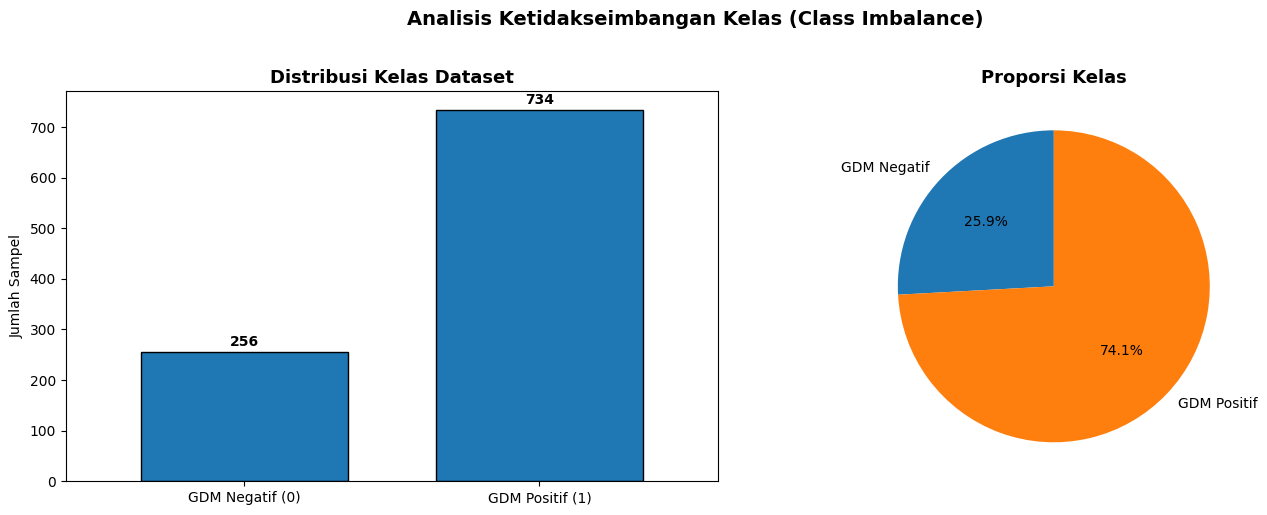

In [11]:
# ---------------------------------------------------------------
# 4.2 Visualisasi distribusi kelas
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(wspace=0.5)

counts = df[TARGET].value_counts()
values = [counts.get(0, 0), counts.get(1, 0)]
labels = ['GDM Negatif (0)', 'GDM Positif (1)']

# Bar chart distribusi kelas
bars = axes[0].bar(
    labels,
    values,
    edgecolor='black',
    width=0.7
)

axes[0].set_title('Distribusi Kelas Dataset', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
axes[0].margins(x=0.15)

for bar in bars:
    v = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        v + 5,
        str(int(v)),
        ha='center',
        va='bottom',
        fontweight='bold'
    )

# Pie chart
axes[1].pie(
    values,
    labels=['GDM Negatif', 'GDM Positif'],
    autopct='%1.1f%%',
    startangle=90
)

axes[1].set_title('Proporsi Kelas', fontsize=13, fontweight='bold')

plt.suptitle(
    'Analisis Ketidakseimbangan Kelas (Class Imbalance)',
    fontsize=14,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.savefig('distribusi_kelas.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# ---------------------------------------------------------------
# 4.3 Pemeriksaan Missing Values Sebelum Pembagian Data
# ---------------------------------------------------------------
missing_info = df[FEATURES].isnull().sum()
missing_pct = (missing_info / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Nama Fitur': missing_info.index,
    'Jumlah Missing': missing_info.values,
    'Persentase (%)': missing_pct.values
})

missing_df = missing_df[missing_df['Jumlah Missing'] > 0]
missing_df = missing_df.sort_values(
    by='Jumlah Missing', ascending=False
).reset_index(drop=True)

if missing_df.empty:
    display(pd.DataFrame({
        'Keterangan': ['Tidak terdapat missing values pada fitur prediktor'],
        'Jumlah Data': [len(df)]
    }))
else:
    display(missing_df)

,Nama Fitur,Jumlah Missing,Persentase (%)
0,h2.1,58,5.86
1,multiP,47,4.75
2,hypo,37,3.74
3,fbs1,28,2.83
4,obesity,12,1.21
5,address,1,0.10
6,arsenic,1,0.10
7,DMsibling,1,0.10
8,wt1,1,0.10
9,ht,1,0.10


## 5. Pembagian Data, Imputasi Median, dan Fitur BMI

Urutan langkah dibuat agar tidak ada informasi data uji yang masuk ke proses pelatihan: data dibagi terlebih dahulu, kemudian median untuk imputasi dihitung **hanya dari data latih** dan diterapkan ke data latih maupun data uji.

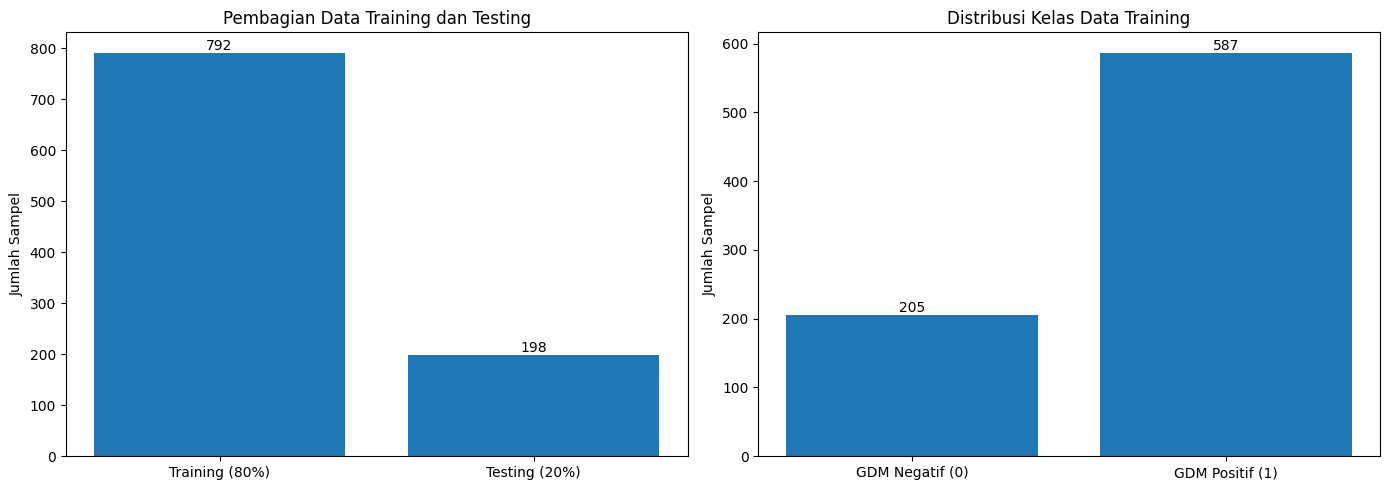

In [13]:
# ---------------------------------------------------------------
# 5.1 Split data 80% training / 20% testing (stratified)
# ---------------------------------------------------------------
X_raw = df[FEATURES].copy()
y_all = df[TARGET].copy()

X_train_raw, X_test_raw, y_train_s, y_test_s = train_test_split(
    X_raw, y_all, test_size=0.2, random_state=42, stratify=y_all
)

y_train = y_train_s.values
y_test = y_test_s.values

# Data training dan testing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(wspace=0.5)

bars1 = axes[0].bar(
    ['Training (80%)', 'Testing (20%)'],
    [len(X_train_raw), len(X_test_raw)]
)

axes[0].set_title('Pembagian Data Training dan Testing')
axes[0].set_ylabel('Jumlah Sampel')

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom'
    )

# Distribusi kelas data training
unique, counts = np.unique(y_train, return_counts=True)

labels_kelas = [
    'GDM Negatif (0)' if u == 0 else 'GDM Positif (1)'
    for u in unique
]

bars2 = axes[1].bar(labels_kelas, counts)

axes[1].set_title('Distribusi Kelas Data Training')
axes[1].set_ylabel('Jumlah Sampel')

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{int(bar.get_height())}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

# Simpan gambar PNG ke folder kerja VS Code
plt.savefig('pembagian_data_training_testing.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [14]:
# ---------------------------------------------------------------
# 5.2 Imputasi Median
# Median dihitung dari data latih saja
# ---------------------------------------------------------------

# Ringkasan missing values sebelum imputasi
tabel_missing_sebelum = pd.DataFrame({
    'Dataset': ['Data Latih', 'Data Uji'],
    'Jumlah Missing': [
        int(X_train_raw.isnull().sum().sum()),
        int(X_test_raw.isnull().sum().sum())
    ]
})

display(tabel_missing_sebelum)

# Imputasi median
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train_raw)

X_train_imp = pd.DataFrame(
    imputer.transform(X_train_raw),
    columns=FEATURES,
    index=X_train_raw.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=FEATURES,
    index=X_test_raw.index
)

# Verifikasi median berasal dari data latih
assert np.allclose(
    imputer.statistics_,
    X_train_raw.median().values,
    equal_nan=True
)

# Ringkasan missing values setelah imputasi
tabel_missing_sesudah = pd.DataFrame({
    'Dataset': ['Data Latih', 'Data Uji'],
    'Jumlah Missing': [
        int(X_train_imp.isnull().sum().sum()),
        int(X_test_imp.isnull().sum().sum())
    ]
})

display(tabel_missing_sesudah)


,Dataset,Jumlah Missing
0,Data Latih,153
1,Data Uji,34


,Dataset,Jumlah Missing
0,Data Latih,0
1,Data Uji,0


In [15]:
# ---------------------------------------------------------------
# 5.3 Hitung BMI sebagai fitur tambahan yang relevan secara klinis
# ---------------------------------------------------------------
# BMI = berat (kg) / tinggi (m)^2
for d in (X_train_imp, X_test_imp):
    d['bmi'] = d['wt1'] / ((d['ht'] / 100) ** 2)

FEATURES_FINAL = FEATURES + ['bmi']

X_train = X_train_imp[FEATURES_FINAL].values
X_test = X_test_imp[FEATURES_FINAL].values

# Tabel informasi fitur
tabel_fitur = pd.DataFrame({
    'Keterangan': ['Jumlah fitur akhir', 'Jumlah data training', 'Jumlah data testing'],
    'Nilai': [
        len(FEATURES_FINAL),
        X_train.shape[0],
        X_test.shape[0]
    ]
})

display(tabel_fitur)

# Tabel statistik BMI
tabel_bmi = X_train_imp['bmi'].describe().round(2).reset_index()
tabel_bmi.columns = ['Statistik BMI', 'Nilai']

display(tabel_bmi)

,Keterangan,Nilai
0,Jumlah fitur akhir,30
1,Jumlah data training,792
2,Jumlah data testing,198


,Statistik BMI,Nilai
0,count,792.00
1,mean,28.82
2,std,5.44
3,min,14.48
4,25%,25.96
5,50%,28.19
6,75%,31.13
7,max,115.74


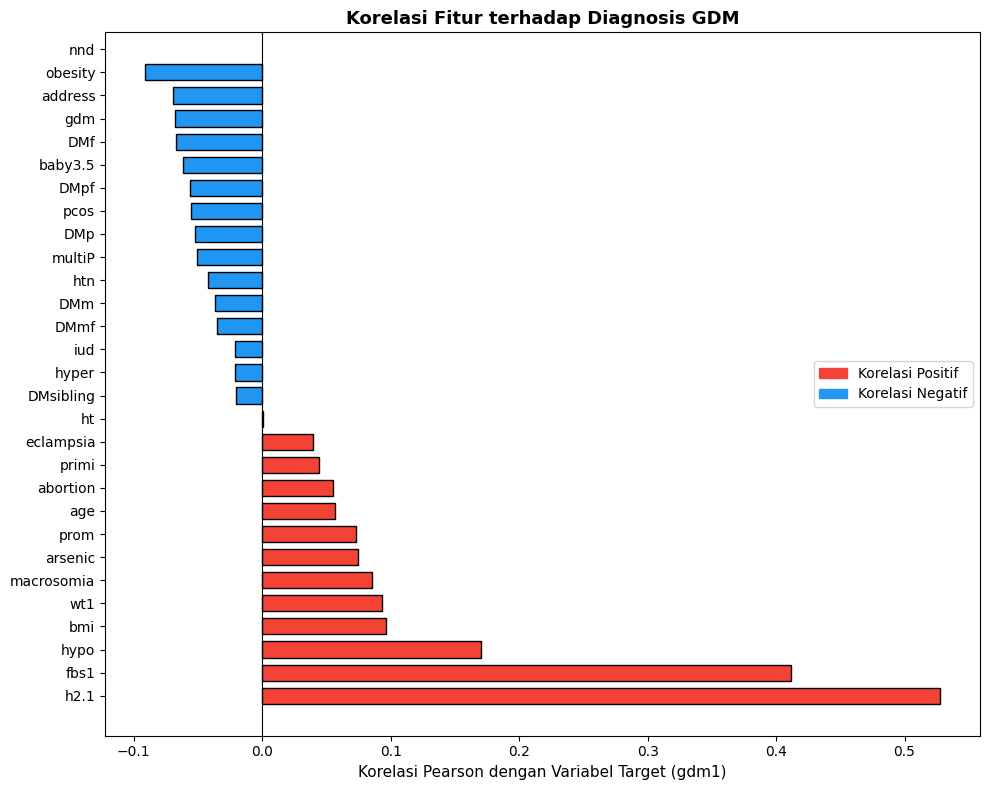

In [16]:
# ---------------------------------------------------------------
# 5.4 Visualisasi korelasi fitur dengan target (data latih)
# ---------------------------------------------------------------
corr_series = X_train_imp[FEATURES_FINAL].corrwith(y_train_s).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
colors = ['#F44336' if c > 0 else '#2196F3' for c in corr_series.values]
bars = plt.barh(corr_series.index, corr_series.values, color=colors, edgecolor='black', height=0.7)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Korelasi Pearson dengan Variabel Target (gdm1)', fontsize=11)
plt.title('Korelasi Fitur terhadap Diagnosis GDM', fontsize=13, fontweight='bold')
red_patch = mpatches.Patch(color='#F44336', label='Korelasi Positif')
blue_patch = mpatches.Patch(color='#2196F3', label='Korelasi Negatif')
plt.legend(handles=[red_patch, blue_patch])
plt.tight_layout()
plt.savefig('korelasi_fitur.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Model Baseline Random Forest (Pembanding Referensi)

Baseline dipakai untuk melihat apakah tuning memberi perbaikan. Baseline **tidak** ikut dalam penentuan model terbaik untuk analisis *feature importance* (RM 1), karena rumusan masalah hanya membandingkan hasil tuning AO dan GWO.

In [17]:
# ---------------------------------------------------------------
# Evaluasi model berdasarkan rumus Dasar Teori (Bab II)
#   Tabel 2.2 : komponen confusion matrix (TP, TN, FP, FN)
#   Pers. 2.8 : Accuracy  = (TP + TN) / (TP + TN + FP + FN)
#   Pers. 2.9 : Precision = TP / (TP + FP)
#   Pers. 2.10: Recall    = TP / (TP + FN)
#   Pers. 2.11: F1-Score  = 2 x (Precision x Recall) / (Precision + Recall)
#   Pers. 2.12: TPR       = TP / (TP + FN)
#   Pers. 2.13: FPR       = FP / (FP + TN)
#   ROC-AUC   : luas di bawah kurva TPR vs FPR pada berbagai ambang
# ---------------------------------------------------------------
def hitung_komponen_cm(y_true, y_pred):
    """Tabel 2.2: hitung TP, TN, FP, FN (kelas positif = 1)."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    return TP, TN, FP, FN


def bagi_aman(pembilang, penyebut):
    """Pembagian dengan penanganan penyebut nol (hasil 0.0)."""
    return pembilang / penyebut if penyebut > 0 else 0.0


def hitung_metrik_manual(y_true, y_pred):
    """Hitung metrik klasifikasi langsung dari rumus Pers. 2.8 - 2.13."""
    TP, TN, FP, FN = hitung_komponen_cm(y_true, y_pred)
    acc  = bagi_aman(TP + TN, TP + TN + FP + FN)        # Pers. 2.8
    prec = bagi_aman(TP, TP + FP)                       # Pers. 2.9
    rec  = bagi_aman(TP, TP + FN)                       # Pers. 2.10
    f1   = bagi_aman(2 * prec * rec, prec + rec)        # Pers. 2.11
    tpr  = bagi_aman(TP, TP + FN)                       # Pers. 2.12
    fpr  = bagi_aman(FP, FP + TN)                       # Pers. 2.13
    return {'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN,
            'Accuracy': acc, 'Precision': prec, 'Recall': rec,
            'F1-Score': f1, 'TPR': tpr, 'FPR': fpr}


def evaluate_model(model, X_test, y_test, model_name='Model', waktu_tuning=None):
    """
    Evaluasi model memakai rumus Bab II, lalu diverifikasi terhadap sklearn.
    Mengembalikan dictionary berisi semua nilai metrik.
    """
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    m = hitung_metrik_manual(y_test, y_pred)

    # ROC-AUC: luas di bawah kurva ROC (TPR terhadap FPR)
    fpr_k, tpr_k, _ = roc_curve(y_test, y_prob)
    m['AUC-ROC'] = hitung_auc(fpr_k, tpr_k)

    # Verifikasi terhadap implementasi sklearn
    cek = {
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall'   : recall_score(y_test, y_pred),
        'F1-Score' : f1_score(y_test, y_pred),
        'AUC-ROC'  : roc_auc_score(y_test, y_prob),
    }
    sesuai = all(np.isclose(m[k], v) for k, v in cek.items())

    print(f'\n===== Evaluasi: {model_name} =====')
    print(f"  Accuracy  : {m['Accuracy']:.4f}")
    print(f"  Precision : {m['Precision']:.4f}")
    print(f"  Recall    : {m['Recall']:.4f}")
    print(f"  F1-Score  : {m['F1-Score']:.4f}")
    print(f"  TPR / FPR : {m['TPR']:.4f} / {m['FPR']:.4f}")
    print(f"  AUC-ROC   : {m['AUC-ROC']:.4f}")
    if waktu_tuning is not None:
        print(f"  Waktu komputasi tuning: {waktu_tuning:.2f} detik")
    print(f"  Verifikasi rumus manual vs sklearn: {'SESUAI' if sesuai else 'TIDAK SESUAI'}")
    print('\nClassification Report:')
    print(classification_report(y_test, y_pred,
                                 target_names=['GDM Negatif', 'GDM Positif']))

    m.update({'Model': model_name, 'y_pred': y_pred, 'y_prob': y_prob})
    return m

print('Fungsi evaluasi (rumus Bab II) siap.')

Fungsi evaluasi (rumus Bab II) siap.


HASIL TRAINING RANDOM FOREST BASELINE
Waktu training: 0.43 detik

===== Evaluasi: RF Baseline =====
  Accuracy  : 0.9293
  Precision : 0.9586
  Recall    : 0.9456
  F1-Score  : 0.9521
  TPR / FPR : 0.9456 / 0.1176
  AUC-ROC   : 0.9638
  Verifikasi rumus manual vs sklearn: SESUAI

Classification Report:
              precision    recall  f1-score   support

 GDM Negatif       0.85      0.88      0.87        51
 GDM Positif       0.96      0.95      0.95       147

    accuracy                           0.93       198
   macro avg       0.90      0.91      0.91       198
weighted avg       0.93      0.93      0.93       198



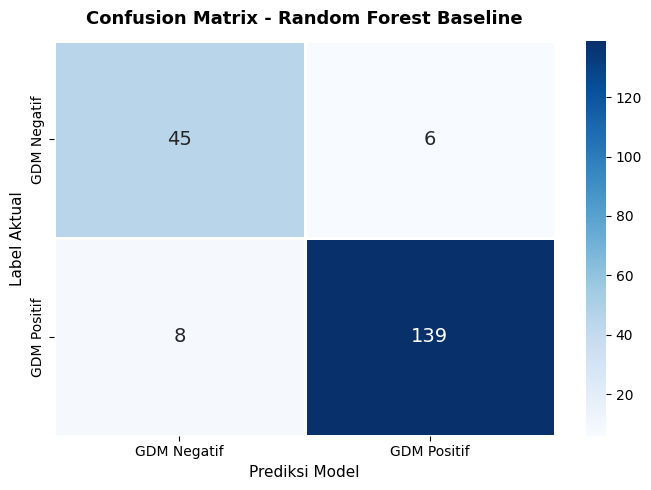

Confusion matrix tersimpan: confusion_matrix_rf_baseline.png

VERIFIKASI PREDIKSI SUARA TERBANYAK
Jumlah pohon (N): 100
Kesesuaian dengan sklearn: 100.00%

Metrik RF Baseline dengan Suara Terbanyak:
Accuracy  : 0.9293
Precision : 0.9586
Recall    : 0.9456
F1-Score  : 0.9521


In [18]:
# ===============================================================
# RANDOM FOREST BASELINE: TRAINING, EVALUASI, DAN SUARA TERBANYAK
# ===============================================================

import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# ---------------------------------------------------------------
# 1. Training model baseline Random Forest
# ---------------------------------------------------------------
t_mulai = time.perf_counter()

rf_baseline = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)
rf_baseline.fit(X_train, y_train)

t_selesai = time.perf_counter()
t_baseline = t_selesai - t_mulai

print('=' * 65)
print('HASIL TRAINING RANDOM FOREST BASELINE')
print('=' * 65)
print(f'Waktu training: {t_baseline:.2f} detik')

# ---------------------------------------------------------------
# 2. Evaluasi baseline
# ---------------------------------------------------------------
results_baseline = evaluate_model(
    rf_baseline, X_test, y_test, 'RF Baseline'
)

# ---------------------------------------------------------------
# 3. Simpan visualisasi confusion matrix
# ---------------------------------------------------------------
y_pred_baseline = rf_baseline.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    xticklabels=['GDM Negatif', 'GDM Positif'],
    yticklabels=['GDM Negatif', 'GDM Positif'],
    annot_kws={'size': 14}
)

plt.title(
    'Confusion Matrix - Random Forest Baseline',
    fontsize=13,
    fontweight='bold',
    pad=12
)
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Aktual', fontsize=11)
plt.tight_layout()

plt.savefig(
    'confusion_matrix_rf_baseline.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close()

print('Confusion matrix tersimpan: confusion_matrix_rf_baseline.png')

# ---------------------------------------------------------------
# 4. Prediksi kelas berdasarkan suara terbanyak (Pers. 2.1)
# ---------------------------------------------------------------
def prediksi_suara_terbanyak(model, X):
    """Prediksi kelas berdasarkan suara terbanyak seluruh pohon."""
    suara = np.array([
        pohon.predict(X) for pohon in model.estimators_
    ]).astype(int)

    y_hat = np.array([
        np.bincount(suara[:, j], minlength=2).argmax()
        for j in range(suara.shape[1])
    ])

    return model.classes_[y_hat]


y_pred_vote = prediksi_suara_terbanyak(rf_baseline, X_test)
y_pred_sk = rf_baseline.predict(X_test)

print('\n' + '=' * 65)
print('VERIFIKASI PREDIKSI SUARA TERBANYAK')
print('=' * 65)
print(f'Jumlah pohon (N): {len(rf_baseline.estimators_)}')
print(
    'Kesesuaian dengan sklearn: '
    f'{(y_pred_vote == y_pred_sk).mean():.2%}'
)

# ---------------------------------------------------------------
# 5. Perhitungan metrik manual berdasarkan Pers. 2.1
# ---------------------------------------------------------------
print('\nMetrik RF Baseline dengan Suara Terbanyak:')

m_vote = hitung_metrik_manual(y_test, y_pred_vote)

for k in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    print(f'{k:10s}: {m_vote[k]:.4f}')

## 7. Aquila Optimizer (AO) untuk Tuning Hyperparameter RF

In [19]:
# ================================================================
# IMPLEMENTASI AQUILA OPTIMIZER (AO)
# Referensi: Abualigah, L., et al. (2021). Aquila Optimizer:
# A Novel Meta-Heuristic Optimization Algorithm.
# Computers & Industrial Engineering, 157, 107250.
# ================================================================

class AquilaOptimizer:
    """
    Aquila Optimizer untuk optimasi hyperparameter Random Forest.
    Mengimplementasikan 4 strategi berburu elang aguila:
      1. Expanded Exploration (high soar)
      2. Narrowed Exploration (contour flight)
      3. Expanded Exploitation (low flight + prey attack)
      4. Narrowed Exploitation (walk & grab)
    """

    def __init__(self, n_agents=10, max_iter=20, random_state=42):
        self.n_agents   = n_agents
        self.max_iter   = max_iter
        self.random_state = random_state

        self.lb = np.array([10,  2,  2,  1, 0.1])
        self.ub = np.array([300, 20, 20, 10, 1.0])
        self.dim = len(self.lb)

        self.convergence_curve = []
        self.n_eval = 0   # jumlah evaluasi fungsi objektif

    def _decode(self, pos):
        pos = np.clip(pos, self.lb, self.ub)
        return {
            'n_estimators'      : int(round(pos[0])),
            'max_depth'         : int(round(pos[1])),
            'min_samples_split' : int(round(pos[2])),
            'min_samples_leaf'  : int(round(pos[3])),
            'max_features'      : float(round(pos[4], 2))
        }

    def _fitness(self, pos, X_tr, y_tr):
        """Fungsi objektif f(theta) = rata-rata F1-Score CV 5-fold.
        Dimaksimalkan: theta* = argmax f(theta)  (Pers. 2.2)."""
        params = self._decode(pos)
        clf = RandomForestClassifier(**params, random_state=self.random_state,
                                     n_jobs=-1)
        cv = StratifiedKFold(n_splits=5, shuffle=True,
                             random_state=self.random_state)
        scores = cross_val_score(clf, X_tr, y_tr, cv=cv,
                                  scoring='f1', n_jobs=-1)
        self.n_eval += 1
        return scores.mean()  # Maksimasi

    def optimize(self, X_tr, y_tr):
        np.random.seed(self.random_state)
        """
        Jalankan algoritma AO dan kembalikan hyperparameter terbaik.
        """
        # Inisialisasi populasi
        X_pop = np.random.uniform(
            self.lb, self.ub, (self.n_agents, self.dim)
        )
        fitness = np.array([self._fitness(X_pop[i], X_tr, y_tr)
                            for i in range(self.n_agents)])

        best_idx   = np.argmax(fitness)
        X_best     = X_pop[best_idx].copy()
        best_score = fitness[best_idx]

        print(f'AO: mulai optimasi ({self.n_agents} agen, {self.max_iter} iterasi)')

        for t in range(1, self.max_iter + 1):
            # Parameter kontrol
            alpha = 0.1
            delta = 0.1
            U     = 0.00565
            r     = 10
            w     = 0.005

            # Rata-rata posisi populasi saat ini
            X_mean = X_pop.mean(axis=0)

            for i in range(self.n_agents):
                rand = np.random.rand()

                if t <= (2/3) * self.max_iter:
                    if rand >= 0.5:
                        # Strategi 1: Expanded Exploration (high soar)
                        X_new = X_best * (1 - t / self.max_iter) + \
                                (X_mean - X_best * np.random.rand())
                    else:
                        # Strategi 2: Narrowed Exploration (contour flight)
                        theta = np.random.uniform(-1, 1, self.dim) * np.pi
                        spiral = (X_best - X_mean) * np.exp(w * np.arange(1, self.dim+1))
                        X_new  = X_best * spiral * np.cos(theta) + X_best
                else:
                    if rand >= 0.5:
                        # Strategi 3: Expanded Exploitation (low flight)
                        X_rand = np.random.uniform(self.lb, self.ub)
                        levy   = self._levy(self.dim)
                        X_new  = (X_best - X_mean) * alpha - \
                                 np.random.rand() + \
                                 ((self.ub - self.lb) * np.random.rand() + self.lb) * levy
                    else:
                        # Strategi 4: Narrowed Exploitation (walk & grab)
                        QF = t ** ((2 * np.random.rand() - 1) / (1 - self.max_iter) ** 2)
                        G1 = 2 * np.random.rand() - 1
                        G2 = 2 * (1 - t / self.max_iter)
                        X_new = QF * X_best - G1 * X_pop[i] * np.random.rand() - \
                                G2 * self._levy(self.dim) + np.random.rand() * G1

                X_new = np.clip(X_new, self.lb, self.ub)
                new_score = self._fitness(X_new, X_tr, y_tr)
                # Pembaruan posisi X(t+1) = X(t) + dX(t) (Pers. 2.3) diterima
                # hanya jika nilai fungsi objektif membaik
                if new_score > fitness[i]:
                    X_pop[i] = X_new
                    fitness[i] = new_score

            best_idx   = np.argmax(fitness)
            if fitness[best_idx] > best_score:
                best_score = fitness[best_idx]
                X_best = X_pop[best_idx].copy()
            X_mean = X_pop.mean(axis=0)

            self.convergence_curve.append(best_score)
            print(f'  Iterasi {t:2d}/{self.max_iter} | '
                  f'F1 terbaik: {best_score:.4f} | '
                  f'Params: {self._decode(X_best)}')

        self.best_params_ = self._decode(X_best)
        self.best_score_  = best_score
        print(f'\nAO selesai. F1 terbaik: {self.best_score_:.4f}')
        print(f'Hyperparameter optimal AO: {self.best_params_}')
        return self.best_params_

    @staticmethod
    def _levy(dim, beta=1.5):
        """Levy flight untuk eksplorasi acak berjangkauan jauh."""
        num    = math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        denom  = math.gamma((1 + beta) / 2) * beta * (2 ** ((beta - 1) / 2))
        sigma  = (num / denom) ** (1 / beta)
        u = np.random.randn(dim) * sigma
        v = np.random.randn(dim)
        return u / (np.abs(v) ** (1 / beta))

In [ ]:
# ---------------------------------------------------------------
# Jalankan Aquila Optimizer
# Anggaran evaluasi disamakan dengan GWO (10 x 20 = 200 evaluasi):
#   GWO : 20 iterasi x 10 serigala              = 200 evaluasi
#   AO  : 10 populasi awal + 19 iterasi x 10    = 200 evaluasi
# Waktu komputasi: T = t_selesai - t_mulai  (Pers. 2.14)
# ---------------------------------------------------------------
t_mulai = time.perf_counter()
ao = AquilaOptimizer(n_agents=10, max_iter=19, random_state=42)
ao_best_params = ao.optimize(X_train, y_train)
t_selesai = time.perf_counter()
t_ao = t_selesai - t_mulai

print(f'\nTotal waktu AO: {t_ao:.2f} detik ({t_ao/60:.1f} menit)')
print(f'Jumlah evaluasi fungsi objektif AO: {ao.n_eval}')


AO: mulai optimasi (10 agen, 19 iterasi)
  Iterasi  1/19 | F1 terbaik: 0.9676 | Params: {'n_estimators': 244, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 7, 'max_features': 0.5}
  Iterasi  2/19 | F1 terbaik: 0.9676 | Params: {'n_estimators': 244, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 7, 'max_features': 0.5}


In [ ]:
# Latih RF dengan hyperparameter terbaik dari AO
rf_ao = RandomForestClassifier(
    **ao_best_params, random_state=42, n_jobs=-1
)
rf_ao.fit(X_train, y_train)
results_ao = evaluate_model(
    rf_ao, X_test, y_test, 'RF + AO',
    waktu_tuning=t_ao
)


===== Evaluasi: RF + AO =====
  Accuracy  : 0.9394
  Precision : 0.9720
  Recall    : 0.9456
  F1-Score  : 0.9586
  TPR / FPR : 0.9456 / 0.0784
  AUC-ROC   : 0.9637
  Waktu komputasi tuning: 161.40 detik
  Verifikasi rumus manual vs sklearn: SESUAI

Classification Report:
              precision    recall  f1-score   support

 GDM Negatif       0.85      0.92      0.89        51
 GDM Positif       0.97      0.95      0.96       147

    accuracy                           0.94       198
   macro avg       0.91      0.93      0.92       198
weighted avg       0.94      0.94      0.94       198



## 8. Grey Wolf Optimizer (GWO) untuk Tuning Hyperparameter RF

In [ ]:
# ================================================================
# IMPLEMENTASI GREY WOLF OPTIMIZER (GWO)
# Referensi: Mirjalili, S., Mirjalili, S.M., & Lewis, A. (2014).
# Grey Wolf Optimizer. Advances in Engineering Software, 69, 46-61.
# ================================================================

class GreyWolfOptimizer:
    """
    Grey Wolf Optimizer untuk optimasi hyperparameter Random Forest.

    Hyperparameter yang dioptimalkan:
      - n_estimators  : jumlah pohon (10 - 300)
      - max_depth     : kedalaman pohon (2 - 20, None jika > 20)
      - min_samples_split : minimal sampel untuk split (2 - 20)
      - min_samples_leaf  : minimal sampel di daun (1 - 10)
      - max_features      : fraksi fitur per split (0.1 - 1.0)
    """

    def __init__(self, n_wolves=10, max_iter=20, random_state=42):
        self.n_wolves   = n_wolves
        self.max_iter   = max_iter
        self.random_state = random_state

        # Batas bawah dan atas setiap dimensi
        self.lb = np.array([10,  2,  2,  1, 0.1])
        self.ub = np.array([300, 20, 20, 10, 1.0])
        self.dim = len(self.lb)

        # Riwayat konvergensi
        self.convergence_curve = []
        self.n_eval = 0   # jumlah evaluasi fungsi objektif

    def _decode(self, pos):
        """Konversi posisi kontinu ke hyperparameter RF."""
        pos = np.clip(pos, self.lb, self.ub)
        return {
            'n_estimators'      : int(round(pos[0])),
            'max_depth'         : int(round(pos[1])),
            'min_samples_split' : int(round(pos[2])),
            'min_samples_leaf'  : int(round(pos[3])),
            'max_features'      : float(round(pos[4], 2)),
        }

    def _fitness(self, pos, X_tr, y_tr):
        """Fungsi objektif f(theta) = rata-rata F1-Score CV 5-fold.
        Dimaksimalkan: theta* = argmax f(theta)  (Pers. 2.2)."""
        params = self._decode(pos)
        clf = RandomForestClassifier(**params, random_state=self.random_state,
                                     n_jobs=-1)
        cv = StratifiedKFold(n_splits=5, shuffle=True,
                             random_state=self.random_state)
        scores = cross_val_score(clf, X_tr, y_tr, cv=cv,
                                  scoring='f1', n_jobs=-1)
        self.n_eval += 1
        return scores.mean()  # Maksimasi

    def optimize(self, X_tr, y_tr):
        np.random.seed(self.random_state)
        """
        Jalankan algoritma GWO dan kembalikan hyperparameter terbaik.
        """
        # Inisialisasi posisi kawanan serigala
        wolves = np.random.uniform(
            self.lb, self.ub, (self.n_wolves, self.dim)
        )

        # Inisialisasi alpha, beta, delta (tiga serigala terbaik)
        alpha_pos, alpha_score = np.zeros(self.dim), -float('inf')
        beta_pos,  beta_score  = np.zeros(self.dim), -float('inf')
        delta_pos, delta_score = np.zeros(self.dim), -float('inf')

        print(f'GWO: mulai optimasi ({self.n_wolves} serigala, {self.max_iter} iterasi)')

        for t in range(self.max_iter):
            for i in range(self.n_wolves):
                score = self._fitness(wolves[i], X_tr, y_tr)
                if score > alpha_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos,  beta_score  = alpha_pos.copy(), alpha_score
                    alpha_pos, alpha_score = wolves[i].copy(), score
                elif score > beta_score:
                    delta_pos, delta_score = beta_pos.copy(), beta_score
                    beta_pos,  beta_score  = wolves[i].copy(), score
                elif score > delta_score:
                    delta_pos, delta_score = wolves[i].copy(), score

            # Perbarui faktor a (menurun linier dari 2 ke 0)
            a = 2.0 - t * (2.0 / self.max_iter)

            for i in range(self.n_wolves):
                for j in range(3):  # Terhadap alpha, beta, delta
                    leader = [alpha_pos, beta_pos, delta_pos][j]
                    r1, r2 = np.random.rand(self.dim), np.random.rand(self.dim)
                    A = 2 * a * r1 - a
                    C = 2 * r2
                    D = np.abs(C * leader - wolves[i])   # Pers. 2.4
                    X = leader - A * D                   # Pers. 2.5 / 2.6
                    if j == 0:
                        X1 = X
                    elif j == 1:
                        X2 = X
                    else:
                        X3 = X
                wolves[i] = np.clip((X1 + X2 + X3) / 3.0, self.lb, self.ub)  # Pers. 2.7

            self.convergence_curve.append(alpha_score)  # F1 terbaik per iterasi
            print(f'  Iterasi {t+1:2d}/{self.max_iter} | '
                  f'F1 terbaik: {alpha_score:.4f} | '
                  f'Params: {self._decode(alpha_pos)}')

        self.best_params_ = self._decode(alpha_pos)
        self.best_score_  = alpha_score
        print(f'\nGWO selesai. F1 terbaik: {self.best_score_:.4f}')
        print(f'Hyperparameter optimal GWO: {self.best_params_}')
        return self.best_params_

In [ ]:
# ---------------------------------------------------------------
# Jalankan GWO
# n_wolves=10, max_iter=20
# Naikkan max_iter=30-50 untuk hasil lebih optimal
# Waktu komputasi: T = t_selesai - t_mulai  (Pers. 2.14)
# ---------------------------------------------------------------
t_mulai = time.perf_counter()
gwo = GreyWolfOptimizer(n_wolves=10, max_iter=20, random_state=42)
gwo_best_params = gwo.optimize(X_train, y_train)
t_selesai = time.perf_counter()
t_gwo = t_selesai - t_mulai

print(f'\nTotal waktu GWO: {t_gwo:.2f} detik ({t_gwo/60:.1f} menit)')
print(f'Jumlah evaluasi fungsi objektif GWO: {gwo.n_eval}')


GWO: mulai optimasi (10 serigala, 20 iterasi)
  Iterasi  1/20 | F1 terbaik: 0.9676 | Params: {'n_estimators': 244, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 7, 'max_features': 0.5}
  Iterasi  2/20 | F1 terbaik: 0.9676 | Params: {'n_estimators': 244, 'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 7, 'max_features': 0.5}
  Iterasi  3/20 | F1 terbaik: 0.9684 | Params: {'n_estimators': 300, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.8}
  Iterasi  4/20 | F1 terbaik: 0.9684 | Params: {'n_estimators': 300, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.8}
  Iterasi  5/20 | F1 terbaik: 0.9684 | Params: {'n_estimators': 300, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.8}
  Iterasi  6/20 | F1 terbaik: 0.9684 | Params: {'n_estimators': 300, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 5, 'max_features': 0.8}
  Iterasi  7/20 | F1 terbaik: 0.9684

In [ ]:
# Latih RF dengan hyperparameter terbaik dari GWO
rf_gwo = RandomForestClassifier(
    **gwo_best_params, random_state=42, n_jobs=-1
)
rf_gwo.fit(X_train, y_train)
results_gwo = evaluate_model(
    rf_gwo, X_test, y_test, 'RF + GWO',
    waktu_tuning=t_gwo
)


===== Evaluasi: RF + GWO =====
  Accuracy  : 0.9394
  Precision : 0.9720
  Recall    : 0.9456
  F1-Score  : 0.9586
  TPR / FPR : 0.9456 / 0.0784
  AUC-ROC   : 0.9608
  Waktu komputasi tuning: 180.11 detik
  Verifikasi rumus manual vs sklearn: SESUAI

Classification Report:
              precision    recall  f1-score   support

 GDM Negatif       0.85      0.92      0.89        51
 GDM Positif       0.97      0.95      0.96       147

    accuracy                           0.94       198
   macro avg       0.91      0.93      0.92       198
weighted avg       0.94      0.94      0.94       198



## 9. Perbandingan Hasil dan Visualisasi

In [ ]:
# ---------------------------------------------------------------
# 9.1 Tabel perbandingan hyperparameter yang ditemukan
# ---------------------------------------------------------------
default_params = {
    'n_estimators': 100, 'max_depth': None,
    'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'
}

params_df = pd.DataFrame({
    'Hyperparameter'   : ['n_estimators', 'max_depth', 'min_samples_split',
                          'min_samples_leaf', 'max_features'],
    'Default RF'       : [default_params[k] for k in
                          ['n_estimators','max_depth','min_samples_split',
                           'min_samples_leaf','max_features']],
    'Optimal GWO'      : [gwo_best_params[k] for k in
                          ['n_estimators','max_depth','min_samples_split',
                           'min_samples_leaf','max_features']],
    'Optimal AO'       : [ao_best_params[k] for k in
                          ['n_estimators','max_depth','min_samples_split',
                           'min_samples_leaf','max_features']],
})

print('Perbandingan Hyperparameter:')
print(params_df.to_string(index=False))

Perbandingan Hyperparameter:
   Hyperparameter Default RF  Optimal GWO  Optimal AO
     n_estimators        100        300.0       244.0
        max_depth       None          9.0         7.0
min_samples_split          2          7.0         4.0
 min_samples_leaf          1          5.0         7.0
     max_features       sqrt          0.8         0.5


In [ ]:
# ---------------------------------------------------------------
# 9.2a Tabel perbandingan metrik evaluasi
# ---------------------------------------------------------------
nama_model = ['RF Baseline', 'RF + AO', 'RF + GWO']
hasil_model = [results_baseline, results_ao, results_gwo]

comparison_df = pd.DataFrame([
    {
        'Model': n,
        'Accuracy': r['Accuracy'],
        'Precision': r['Precision'],
        'Recall': r['Recall'],
        'F1-Score': r['F1-Score'],
        'ROC-AUC': r['AUC-ROC'],
    }
    for n, r in zip(nama_model, hasil_model)
]).set_index('Model')

print('Tabel Perbandingan Metrik Evaluasi:')
display(comparison_df.round(4))

Tabel Perbandingan Metrik Evaluasi:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
RF Baseline,0.9293,0.9586,0.9456,0.9521,0.9638
RF + AO,0.9394,0.9720,0.9456,0.9586,0.9637
RF + GWO,0.9394,0.9720,0.9456,0.9586,0.9608


In [ ]:
# ---------------------------------------------------------------
# 9.2b Tabel confusion matrix dan efisiensi komputasi
# ---------------------------------------------------------------
nama_model = ['RF Baseline', 'RF + AO', 'RF + GWO']
hasil_model = [results_baseline, results_ao, results_gwo]

waktu_model = [t_baseline, t_ao, t_gwo]
evaluasi_objektif = [np.nan, ao.n_eval, gwo.n_eval]

confusion_df = pd.DataFrame([
    {
        'Model': n,
        'TN': r['TN'],
        'TP': r['TP'],
        'FP': r['FP'],
        'FN': r['FN'],
        'TPR': r['TPR'],
        'FPR': r['FPR'],
        'Waktu Komputasi (detik)': waktu,
        'Evaluasi Fungsi Objektif': evaluasi
    }
    for n, r, waktu, evaluasi in zip(
        nama_model, hasil_model, waktu_model, evaluasi_objektif
    )
]).set_index('Model')

print('Tabel Confusion Matrix dan Efisiensi Komputasi:')
display(confusion_df.round(4))

Tabel Confusion Matrix dan Efisiensi Komputasi:


,TN,TP,FP,FN,TPR,FPR,Waktu Komputasi (detik),Evaluasi Fungsi Objektif
Model,,,,,,,,
RF Baseline,45,139,6,8,0.9456,0.1176,0.2101,NaN
RF + AO,47,139,4,8,0.9456,0.0784,161.4033,200.0
RF + GWO,47,139,4,8,0.9456,0.0784,180.1133,200.0


In [ ]:

# ---------------------------------------------------------------
# 9.3 RUMUSAN MASALAH 2: Perbandingan RF + AO vs RF + GWO
# ---------------------------------------------------------------

KOLOM_METRIK = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
KOLOM_WAKTU = 'Waktu Komputasi (detik)'

hasil_tuning = {
    'RF + GWO': (results_gwo, t_gwo),
    'RF + AO': (results_ao, t_ao),
}

# Membuat tabel perbandingan
rm2_df = pd.DataFrame({
    nama: {
        **{m: r[m] for m in KOLOM_METRIK},
        KOLOM_WAKTU: waktu
    }
    for nama, (r, waktu) in hasil_tuning.items()
}).T

# ---------------------------------------------------------------
# Menentukan pemenang setiap metrik
# ---------------------------------------------------------------
pemenang_metrik = {}

for kol in KOLOM_METRIK + [KOLOM_WAKTU]:
    gwo_val = rm2_df.loc['RF + GWO', kol]
    ao_val = rm2_df.loc['RF + AO', kol]

    if np.isclose(gwo_val, ao_val, atol=0.00005):
        pemenang_metrik[kol] = 'Seri'
    elif kol == KOLOM_WAKTU:
        pemenang_metrik[kol] = (
            'RF + GWO' if gwo_val < ao_val else 'RF + AO'
        ) + ' (lebih cepat)'
    else:
        pemenang_metrik[kol] = (
            'RF + GWO' if gwo_val > ao_val else 'RF + AO'
        )

# ---------------------------------------------------------------
# Menentukan model terbaik berdasarkan kriteria penelitian
# F1-Score tertinggi -> ROC-AUC tertinggi -> waktu tercepat
# ---------------------------------------------------------------
def pilih_model_terbaik(df):
    urut = df.sort_values(
        ['F1-Score', 'AUC-ROC', KOLOM_WAKTU],
        ascending=[False, False, True]
    )

    a, b = urut.iloc[0], urut.iloc[1]

    if not np.isclose(a['F1-Score'], b['F1-Score']):
        alasan = 'F1-Score tertinggi'
    elif not np.isclose(a['AUC-ROC'], b['AUC-ROC']):
        alasan = 'F1-Score seri, ROC-AUC lebih tinggi'
    elif not np.isclose(a[KOLOM_WAKTU], b[KOLOM_WAKTU]):
        alasan = 'F1-Score dan ROC-AUC seri, waktu lebih cepat'
    else:
        alasan = 'Seluruh kriteria seri'

    return urut.index[0], alasan

model_terbaik_nama, alasan_terbaik = pilih_model_terbaik(rm2_df)

# ---------------------------------------------------------------
# Menggabungkan hasil ke satu tabel
# ---------------------------------------------------------------
tabel_perbandingan = rm2_df.copy()

tabel_perbandingan['Pemenang Accuracy'] = pemenang_metrik['Accuracy']
tabel_perbandingan['Pemenang Precision'] = pemenang_metrik['Precision']
tabel_perbandingan['Pemenang Recall'] = pemenang_metrik['Recall']
tabel_perbandingan['Pemenang F1-Score'] = pemenang_metrik['F1-Score']
tabel_perbandingan['Pemenang ROC-AUC'] = pemenang_metrik['AUC-ROC']
tabel_perbandingan['Pemenang Waktu'] = pemenang_metrik[KOLOM_WAKTU]

tabel_perbandingan['Model Terbaik'] = [
    'Terpilih' if nama == model_terbaik_nama else '-'
    for nama in tabel_perbandingan.index
]

print('Tabel Perbandingan AO dan GWO:')
display(tabel_perbandingan.round(4))

print(f'\nModel terbaik: {model_terbaik_nama}')
print(f'Alasan pemilihan: {alasan_terbaik}')


Tabel Perbandingan AO dan GWO:

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Waktu Komputasi (detik),Pemenang Accuracy,Pemenang Precision,Pemenang Recall,Pemenang F1-Score,Pemenang ROC-AUC,Pemenang Waktu,Model Terbaik
RF + GWO,0.9394,0.972,0.9456,0.9586,0.9608,180.1133,Seri,Seri,Seri,Seri,RF + AO,RF + AO (lebih cepat),-
RF + AO,0.9394,0.972,0.9456,0.9586,0.9637,161.4033,Seri,Seri,Seri,Seri,RF + AO,RF + AO (lebih cepat),Terpilih



Model terbaik: RF + AO
Alasan pemilihan: F1-Score seri, ROC-AUC lebih tinggi


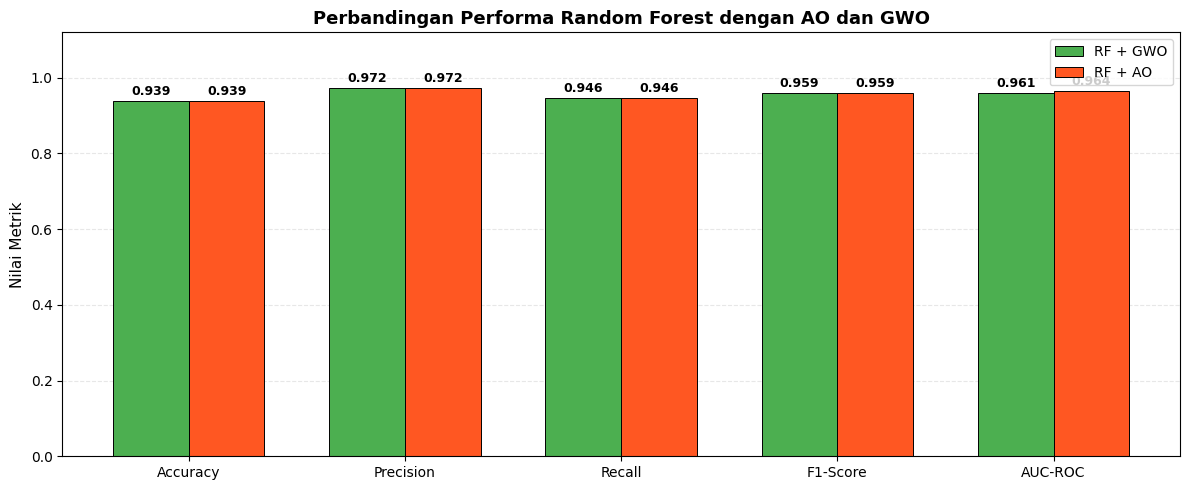

In [ ]:
# ---------------------------------------------------------------
# 9.4 Bar chart perbandingan metrik AO dan GWO
# ---------------------------------------------------------------

metrics_list = [
    'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC'
]

fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(metrics_list))
w = 0.35

colors = ['#4CAF50', '#FF5722']
models = ['RF + GWO', 'RF + AO']
results_all = [results_gwo, results_ao]

for i, (model, res, color) in enumerate(
    zip(models, results_all, colors)
):
    vals = [res[m] for m in metrics_list]

    bars = ax.bar(
        x + (i - 0.5) * w,
        vals,
        w,
        label=model,
        color=color,
        edgecolor='black',
        linewidth=0.7
    )

    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.008,
            f'{val:.3f}',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold'
        )

ax.set_xticks(x)
ax.set_xticklabels(metrics_list, fontsize=10)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Nilai Metrik', fontsize=11)
ax.set_title(
    'Perbandingan Performa Random Forest dengan AO dan GWO',
    fontsize=13,
    fontweight='bold'
)

ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    'perbandingan_metrik_ao_gwo.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

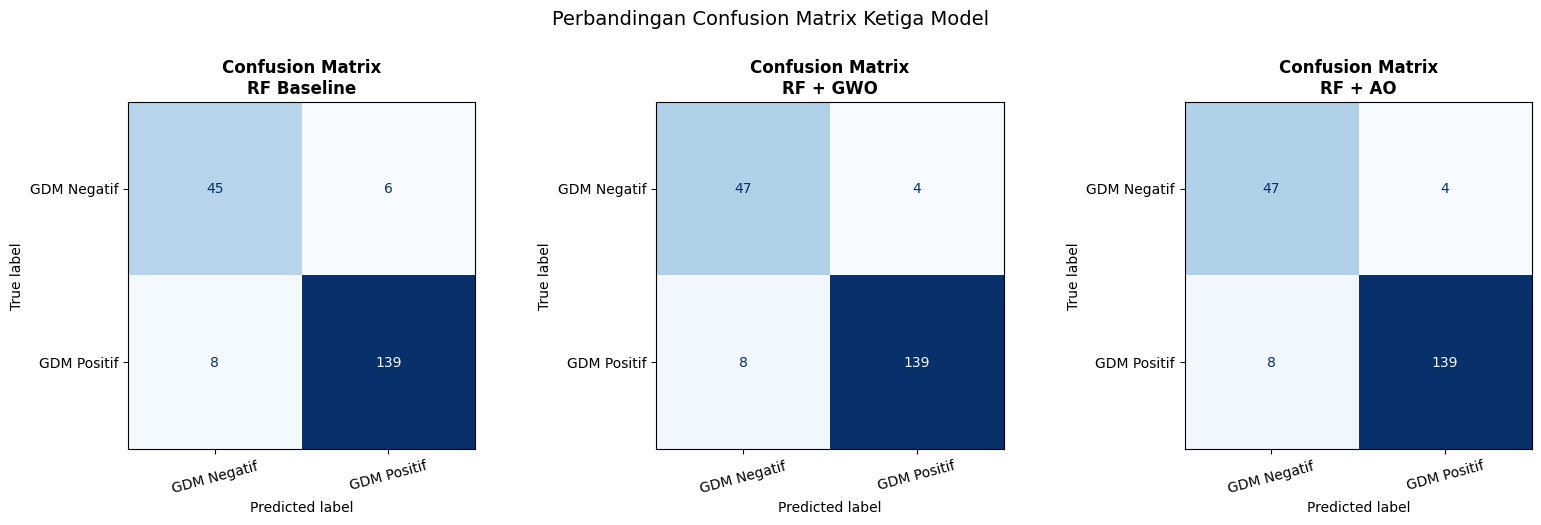

In [ ]:
# ---------------------------------------------------------------
# 9.5 Confusion Matrix ketiga model
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
class_names = ['GDM Negatif', 'GDM Positif']

for ax, (model_name, model) in zip(axes, [
    ('RF Baseline', rf_baseline),
    ('RF + GWO', rf_gwo),
    ('RF + AO', rf_ao)
]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix\n{model_name}', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', labelrotation=15)

plt.suptitle('Perbandingan Confusion Matrix Ketiga Model', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ---------------------------------------------------------------
# 9.6 Pers. 2.1 pada ketiga model: suara terbanyak vs prediksi sklearn
# ---------------------------------------------------------------
baris = []

for n, mdl in [
    ('RF Baseline', rf_baseline),
    ('RF + GWO', rf_gwo),
    ('RF + AO', rf_ao)
]:
    yv = prediksi_suara_terbanyak(mdl, X_test)
    mv = hitung_metrik_manual(y_test, yv)

    baris.append({
        'Model': n,
        'Jumlah pohon (N)': len(mdl.estimators_),
        'Kesesuaian dgn sklearn': (yv == mdl.predict(X_test)).mean(),
        'Accuracy': mv['Accuracy'],
        'Precision': mv['Precision'],
        'Recall': mv['Recall'],
        'F1-Score': mv['F1-Score']
    })

# Tampilkan hasil dalam bentuk tabel
tabel_perbandingan = pd.DataFrame(baris).set_index('Model').round(4)

display(tabel_perbandingan)

,Jumlah pohon (N),Kesesuaian dgn sklearn,Accuracy,Precision,Recall,F1-Score
Model,,,,,,
RF Baseline,100,1.0,0.9293,0.9586,0.9456,0.9521
RF + GWO,300,1.0,0.9394,0.9720,0.9456,0.9586
RF + AO,244,1.0,0.9394,0.9720,0.9456,0.9586


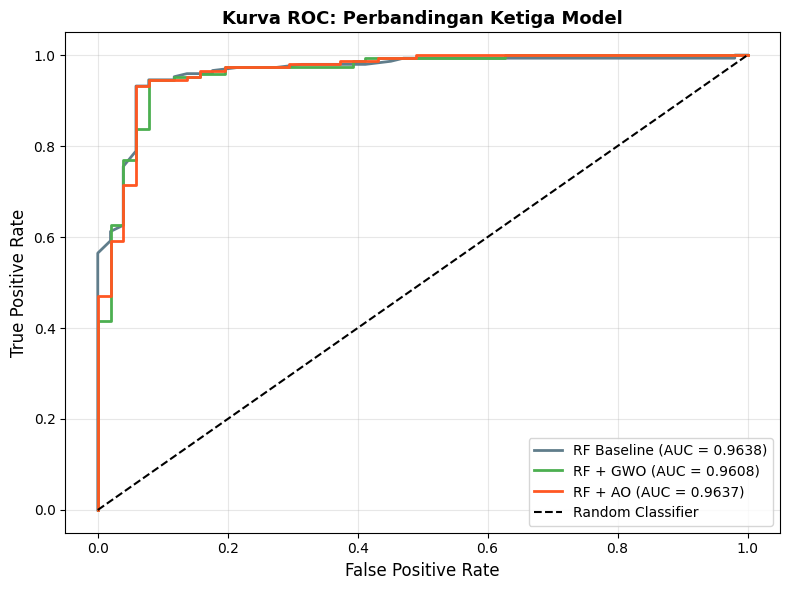

In [ ]:
# ---------------------------------------------------------------
# 9.5 Kurva ROC ketiga model
# ---------------------------------------------------------------
plt.figure(figsize=(8, 6))

for model_name, model, color in [
    ('RF Baseline', rf_baseline, '#607D8B'),
    ('RF + GWO',    rf_gwo,      '#4CAF50'),
    ('RF + AO',     rf_ao,       '#FF5722'),
]:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{model_name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Kurva ROC: Perbandingan Ketiga Model', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

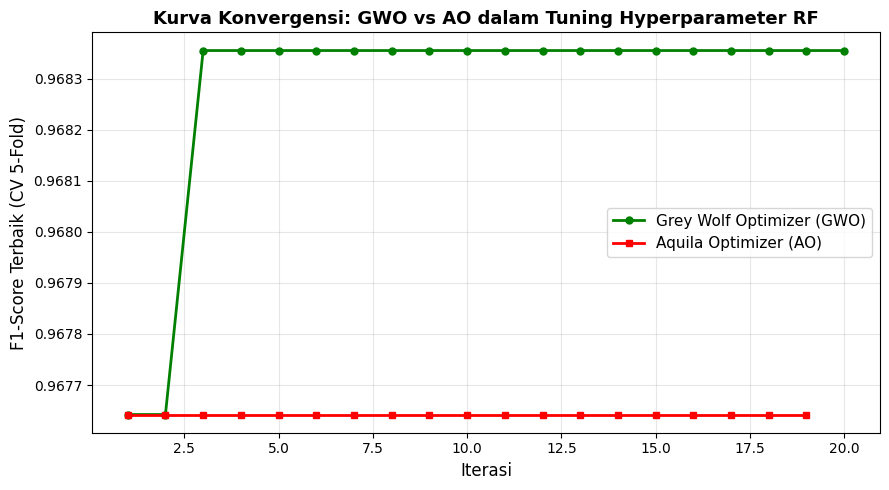

In [ ]:
# ---------------------------------------------------------------
# 9.6 Kurva konvergensi GWO vs AO
# ---------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(gwo.convergence_curve)+1), gwo.convergence_curve,
         'g-o', lw=2, markersize=5, label='Grey Wolf Optimizer (GWO)')
plt.plot(range(1, len(ao.convergence_curve)+1), ao.convergence_curve,
         'r-s', lw=2, markersize=5, label='Aquila Optimizer (AO)')
plt.xlabel('Iterasi', fontsize=12)
plt.ylabel('F1-Score Terbaik (CV 5-Fold)', fontsize=12)
plt.title('Kurva Konvergensi: GWO vs AO dalam Tuning Hyperparameter RF',
          fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('convergence_curve.png', dpi=150, bbox_inches='tight')
plt.show()

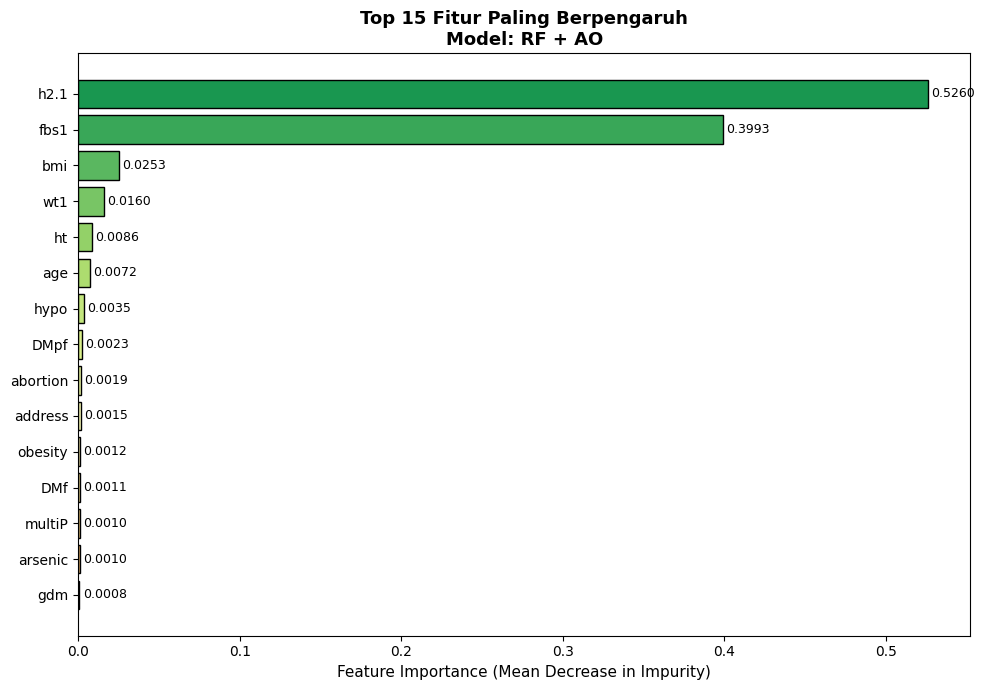

In [ ]:
# ---------------------------------------------------------------
# 9.7 Feature Importance dari model terbaik
# ---------------------------------------------------------------

best_model_name = model_terbaik_nama

if best_model_name == 'RF + AO':
    best_model_obj = rf_ao
else:
    best_model_obj = rf_gwo

importances = best_model_obj.feature_importances_

fi_df = pd.DataFrame({
    'Fitur': FEATURES_FINAL,
    'Importance': importances
}).sort_values('Importance', ascending=True)

# Tampilkan top 15
fi_top = fi_df.tail(15)

plt.figure(figsize=(10, 7))
colors = plt.cm.RdYlGn(
    np.linspace(0.3, 0.9, len(fi_top))
)

bars = plt.barh(
    fi_top['Fitur'],
    fi_top['Importance'],
    color=colors,
    edgecolor='black'
)

for bar in bars:
    nilai = bar.get_width()
    plt.text(
        nilai + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f'{nilai:.4f}',
        va='center',
        fontsize=9
    )

plt.xlabel(
    'Feature Importance (Mean Decrease in Impurity)',
    fontsize=11
)
plt.title(
    f'Top 15 Fitur Paling Berpengaruh\nModel: {best_model_name}',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    'feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 10. Ringkasan Akhir

In [ ]:
# ---------------------------------------------------------------
# Cetak ringkasan lengkap untuk laporan skripsi
# ---------------------------------------------------------------
print('=' * 65)
print('RINGKASAN HASIL PENELITIAN')
print('Perbandingan AO vs GWO dalam Tuning RF untuk Deteksi GDM')
print('=' * 65)

# Informasi dataset
dataset_df = pd.DataFrame({
    'Keterangan': ['Dataset', 'Total Sampel', 'Data Training',
                   'Data Testing', 'Jumlah Fitur'],
    'Nilai': [
        'Mendeley GDM (DOI: 10.17632/k5c8rfgsn9/1)',
        len(X_train) + len(X_test),
        len(X_train),
        len(X_test),
        len(FEATURES_FINAL)
    ]
})

print('\nInformasi Dataset:')
display(dataset_df)

# Hyperparameter optimal
hyperparameter_df = pd.DataFrame([
    {'Metode': 'GWO', 'Hyperparameter Optimal': str(gwo_best_params)},
    {'Metode': 'AO', 'Hyperparameter Optimal': str(ao_best_params)}
])

print('\nHyperparameter Optimal:')
display(hyperparameter_df)

# Performa model
print('\nPerforma Model:')
display(comparison_df.round(4))

# Waktu komputasi
waktu_ringkasan_df = pd.DataFrame({
    'Model': ['RF Baseline', 'RF + GWO', 'RF + AO'],
    'Waktu Komputasi (detik)': [t_baseline, t_gwo, t_ao],
    'Waktu Komputasi (menit)': [
        t_baseline / 60, t_gwo / 60, t_ao / 60
    ],
    'Evaluasi Fungsi Objektif': [
        np.nan, gwo.n_eval, ao.n_eval
    ]
})

print('\nWaktu Komputasi:')
display(waktu_ringkasan_df.round(2))

# Perbandingan AO vs GWO
print('\nJawaban Rumusan Masalah 2: AO vs GWO')
display(rm2_df.round(4))

kesimpulan_df = pd.DataFrame([{
    'Model Terbaik': model_terbaik_nama,
    'Alasan Pemilihan': alasan_terbaik,
    'F1-Score': rm2_df.loc[model_terbaik_nama, 'F1-Score'],
    'AUC-ROC': rm2_df.loc[model_terbaik_nama, 'AUC-ROC'],
    'F1-Score RF Baseline': results_baseline['F1-Score'],
    'AUC-ROC RF Baseline': results_baseline['AUC-ROC']
}]).round(4)

display(kesimpulan_df)

# Top 5 fitur paling berpengaruh
print('\nJawaban Rumusan Masalah 1: Fitur Paling Berpengaruh')

top5_df = (
    fi_df.tail(5)
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

top5_df.index = top5_df.index + 1
top5_df.index.name = 'Peringkat'
top5_df = top5_df.rename(columns={
    'Fitur': 'Nama Fitur',
    'Importance': 'Feature Importance'
})

display(top5_df.round(4))

print('=' * 65)

RINGKASAN HASIL PENELITIAN
Perbandingan AO vs GWO dalam Tuning RF untuk Deteksi GDM

Informasi Dataset:


,Keterangan,Nilai
0,Dataset,Mendeley GDM (DOI: 10.17632/k5c8rfgsn9/1)
1,Total Sampel,990
2,Data Training,792
3,Data Testing,198
4,Jumlah Fitur,30



Hyperparameter Optimal:


,Metode,Hyperparameter Optimal
0,GWO,"{'n_estimators': 300, 'max_depth': 9, 'min_sam..."
1,AO,"{'n_estimators': 244, 'max_depth': 7, 'min_sam..."



Performa Model:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
RF Baseline,0.9293,0.9586,0.9456,0.9521,0.9638
RF + AO,0.9394,0.9720,0.9456,0.9586,0.9637
RF + GWO,0.9394,0.9720,0.9456,0.9586,0.9608


... (3 outputs left out)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Waktu Komputasi (detik)
RF + GWO,0.9394,0.972,0.9456,0.9586,0.9608,180.1133
RF + AO,0.9394,0.972,0.9456,0.9586,0.9637,161.4033


,Model Terbaik,Alasan Pemilihan,F1-Score,AUC-ROC,F1-Score RF Baseline,AUC-ROC RF Baseline
0,RF + AO,"F1-Score seri, ROC-AUC lebih tinggi",0.9586,0.9637,0.9521,0.9638



Jawaban Rumusan Masalah 1: Fitur Paling Berpengaruh


,Nama Fitur,Feature Importance
Peringkat,,
1,h2.1,0.5260
2,fbs1,0.3993
3,bmi,0.0253
4,wt1,0.0160
5,ht,0.0086


## 11. Penyimpanan Model dan Logging MLflow

Bagian ini menyimpan model terbaik untuk aplikasi website dan mencatat seluruh eksperimen ke MLflow. Keluarannya ada di folder `artifacts/` (dibaca oleh aplikasi) dan `mlflow.db` (dilihat dengan `mlflow ui`).

In [ ]:
# ---------------------------------------------------------------
# 11.1 Threshold terbaik
# Dicari dari probabilitas out-of-fold pada DATA LATIH (validasi silang 5 lipatan)
# sehingga data uji tidak ikut menentukan threshold.
# ---------------------------------------------------------------
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

model_terbaik_nama = best_model_name

if model_terbaik_nama == 'RF + AO':
    model_terbaik_obj = rf_ao
else:
    model_terbaik_obj = rf_gwo

cv_thr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prob_oof = cross_val_predict(clone(model_terbaik_obj), X_train, y_train, cv=cv_thr,
                             method='predict_proba', n_jobs=-1)[:, 1]
kandidat_thr = np.round(np.arange(0.10, 0.901, 0.01), 2)
f1_oof_list = [f1_score(y_train, (prob_oof >= t).astype(int), zero_division=0)
               for t in kandidat_thr]
idx_thr = int(np.argmax(f1_oof_list))
thr_terbaik = float(kandidat_thr[idx_thr])
f1_oof = float(f1_oof_list[idx_thr])

prob_uji = model_terbaik_obj.predict_proba(X_test)[:, 1]
f1_uji_thr = f1_score(y_test, (prob_uji >= thr_terbaik).astype(int), zero_division=0)
f1_uji_05  = f1_score(y_test, (prob_uji >= 0.5).astype(int), zero_division=0)

print(f'Threshold terbaik (data latih, out-of-fold): {thr_terbaik:.2f} (F1 {f1_oof:.4f})')
print(f'F1 data uji dengan threshold tersebut : {f1_uji_thr:.4f}')
print(f'F1 data uji dengan threshold 0,5      : {f1_uji_05:.4f}')


Threshold terbaik (data latih, out-of-fold): 0.50 (F1 0.9676)
F1 data uji dengan threshold tersebut : 0.9586
F1 data uji dengan threshold 0,5      : 0.9586


In [ ]:

# ---------------------------------------------------------------
# 11.2 Simpan ketiga model, imputer, daftar fitur, dan metadata
# ---------------------------------------------------------------
import json
import joblib
import sklearn

ARTIFACT_DIR = ROOT / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Threshold yang digunakan aplikasi
threshold_dipakai = 0.5

# Daftar model yang akan disimpan
daftar_model = {
    'baseline': {
        'model': rf_baseline,
        'nama_model': 'RF Baseline',
        'threshold_terbaik': 0.5,
    },
    'gwo': {
        'model': rf_gwo,
        'nama_model': 'RF + GWO',
        'threshold_terbaik': 0.5,
    },
    'ao': {
        'model': rf_ao,
        'nama_model': 'RF + AO',
        'threshold_terbaik': 0.5,
    },
}

# Simpan masing-masing model
for nama_file, info in daftar_model.items():

    bundle = {
        'model': info['model'],
        'imputer': imputer,
        'features': list(FEATURES),
        'features_final': list(FEATURES_FINAL),
        'nama_model': info['nama_model'],
        'threshold_terbaik': info['threshold_terbaik'],
        'threshold_dipakai': threshold_dipakai,
        'versi_sklearn': sklearn.__version__,
    }

    path_model = ARTIFACT_DIR / f'model_{nama_file}.pkl'
    joblib.dump(bundle, path_model)

    print(f'{info["nama_model"]} tersimpan: {path_model}')

# ---------------------------------------------------------------
# Simpan metadata formulir (cukup satu file untuk ketiga model)
# ---------------------------------------------------------------
label_kolom = meta.column_names_to_labels or {}
label_nilai = meta.variable_value_labels or {}

meta_fitur = {}

for f in FEATURES:
    pilihan = label_nilai.get(f)

    meta_fitur[f] = {
        'label': label_kolom.get(f) or f,
        'pilihan': (
            [
                {'nilai': float(k), 'label': str(v)}
                for k, v in pilihan.items()
            ]
            if pilihan else None
        ),
    }

with open(
    ARTIFACT_DIR / 'metadata_fitur.json',
    'w',
    encoding='utf-8'
) as fh:
    json.dump(meta_fitur, fh, indent=2, ensure_ascii=False)

print('\nSemua artifact berhasil disiapkan:')
for nama in [
    'model_baseline.pkl',
    'model_gwo.pkl',
    'model_ao.pkl',
    'metadata_fitur.json'
]:
    print(f'  - {nama}')

print('\nLokasi penyimpanan:')
print(ARTIFACT_DIR.resolve())

print('\nIsi folder artifacts:')
for file in ARTIFACT_DIR.iterdir():
    print(f'- {file.name}')


Model terbaik (RF + AO) tersimpan di d:\SEMESTER 7\S WORD\gdm_ao_gwo_rf\artifacts
  model_gdm.pkl, metadata_fitur.json


In [ ]:
# ---------------------------------------------------------------
# 11.3 Upload model dan metadata ke Hugging Face Spaces
# ---------------------------------------------------------------
import os
from dotenv import load_dotenv
from huggingface_hub import HfApi

# Membaca konfigurasi dari file .env
load_dotenv(ROOT / ".env")

HF_TOKEN = os.getenv("HF_TOKEN")
HF_REPO_ID = os.getenv("HF_REPO_ID")

if not HF_TOKEN:
    raise ValueError("HF_TOKEN belum diatur di file .env")

if not HF_REPO_ID:
    raise ValueError("HF_REPO_ID belum diatur di file .env")

# Upload model dan metadata
api = HfApi(token=HF_TOKEN)

api.upload_folder(
    folder_path=str(ARTIFACT_DIR),
    path_in_repo="artifacts",
    repo_id=HF_REPO_ID,
    repo_type="space",
    commit_message=f"Update model GDM: {model_terbaik_nama}"
)

print(f"Model terbaik ({model_terbaik_nama}) berhasil diunggah.")

Model terbaik (RF + AO) berhasil diunggah.


In [ ]:
# ---------------------------------------------------------------
# 11.3 Logging eksperimen dengan MLflow
# Setiap model menjadi satu run: parameter, metrik, confusion matrix,
# classification report, dan (untuk model terbaik) threshold, feature importance,
# grafik, serta model hasil pelatihan.
# ---------------------------------------------------------------
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri('sqlite:///' + (ROOT / 'mlflow.db').as_posix())
mlflow.set_experiment('gdm_ao_gwo_rf')

NAMA_HP = ['n_estimators', 'max_depth', 'min_samples_split',
           'min_samples_leaf', 'max_features']
daftar_run = [
    # nama, model, hasil evaluasi, waktu komputasi, jumlah evaluasi, hyperparameter
    ('RF Baseline', rf_baseline, results_baseline, t_baseline, None,
     {k: rf_baseline.get_params()[k] for k in NAMA_HP}),
    ('RF + GWO', rf_gwo, results_gwo, t_gwo, gwo.n_eval, gwo_best_params),
    ('RF + AO',  rf_ao,  results_ao,  t_ao,  ao.n_eval,  ao_best_params),
]
file_grafik = [p for p in ['perbandingan_metrik.png', 'confusion_matrix.png', 'roc_curve.png',
                           'convergence_curve.png', 'feature_importance.png']
               if Path(p).exists()]

for nama, mdl, hasil, waktu, n_eval, hp in daftar_run:
    terbaik = (nama == model_terbaik_nama)
    with mlflow.start_run(run_name=nama):
        mlflow.log_params({**hp, 'random_state': 42, 'test_size': 0.2, 'cv_folds': 5,
                           'jumlah_fitur': len(FEATURES_FINAL), 'threshold_evaluasi': 0.5})
        mlflow.log_metrics({
            'accuracy': hasil['Accuracy'], 'precision': hasil['Precision'],
            'recall': hasil['Recall'], 'f1_score': hasil['F1-Score'],
            'roc_auc': hasil['AUC-ROC'], 'tpr': hasil['TPR'], 'fpr': hasil['FPR'],
            'waktu_komputasi_detik': waktu,
        })
        if n_eval:
            mlflow.log_metric('jumlah_evaluasi', n_eval)
        mlflow.log_dict({k: int(hasil[k]) for k in ('TP', 'TN', 'FP', 'FN')},
                        'confusion_matrix.json')
        mlflow.log_text(classification_report(y_test, hasil['y_pred'],
                                              target_names=['GDM Negatif', 'GDM Positif']),
                        'classification_report.txt')
        mlflow.set_tag('model_terbaik', str(terbaik))

        if terbaik:
            mlflow.log_metric('threshold_terbaik', thr_terbaik)
            mlflow.log_metric('f1_oof_threshold_terbaik', f1_oof)
            mlflow.log_metric('f1_uji_threshold_terbaik', f1_uji_thr)
            mlflow.log_text(fi_df.sort_values('Importance', ascending=False)
                            .to_csv(index=False), 'feature_importance.csv')
            for berkas in file_grafik:
                mlflow.log_artifact(berkas, artifact_path='grafik')
            # Model dibuat sendiri di notebook ini (sumber tepercaya), jadi cloudpickle dipakai.
            # Format skops bawaan MLflow 3 menolak objek pohon scikit-learn.
            try:
                mlflow.sklearn.log_model(mdl, name='model', serialization_format='cloudpickle')
            except TypeError:   # MLflow versi lama memakai artifact_path
                mlflow.sklearn.log_model(mdl, artifact_path='model',
                                         serialization_format='cloudpickle')

print('MLflow: 3 run tercatat. Lihat dengan perintah berikut dari folder proyek:')
print('  mlflow ui --backend-store-uri sqlite:///mlflow.db')


2026/11/02 21:43:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


MLflow: 3 run tercatat. Lihat dengan perintah berikut dari folder proyek:
  mlflow ui --backend-store-uri sqlite:///mlflow.db
